# Image Warping Lab

## Part 1: Interpolation

Since we are going to be warping images, we need to make sure we have a good interpolation function to deal with inexact pixel locations.

In the cell below, we want to scale an image by a factor of 2.30 in both x and y. **Write a function called "interpolate" that performs bilinear interpolation.** This function should take in the image and a location (x,y) of interest. It then uses the nearby pixels to interpolate and return an RGB value.

**Note:** For this lab, we will keep images as floats to simplify the interpolation. Thus, output your images as values between 0-1, not 0-255.

In [4]:
def interpolate(img, x, y):
    """
    Bilinear interpolation for a single point (x, y)
    Inputs:
        img : HxWxC float array, values in [0,1]
        x,y : float pixel coordinates (x → cols, y → rows)
    Returns:
        RGB tuple of interpolated value
    """
    H, W, C = img.shape

    # Handle edges
    if x < 0 or y < 0 or x >= W - 1 or y >= H - 1:
        return np.zeros(C)

    x0, y0 = int(np.floor(x)), int(np.floor(y))
    x1, y1 = x0 + 1, y0 + 1

    # Fractions
    dx, dy = x - x0, y - y0

    # Interpolate
    Ia = img[y0, x0]
    Ib = img[y0, x1]
    Ic = img[y1, x0]
    Id = img[y1, x1]

    wa = (1 - dx) * (1 - dy)
    wb = dx * (1 - dy)
    wc = (1 - dx) * dy
    wd = dx * dy

    return wa*Ia + wb*Ib + wc*Ic + wd*Id

## Part 2: Compose (i.e. Backwards Mapping)

Now that we have a interpolation function, we need a function that can compose a source image onto a target image given a transform. In Lab 3, we used Pillow's built-in compose function. You will now implement this yourself using backwards mapping. **This function should also call your interpolate function.**

To implement this function,
- Invert the given transformation. (This is really easy using the NumPy *linalg* library)
- For each pixel in the target image
  - Determine the x and y coordinates of the pixel
  - Homogenize the coordinate
  - Multiply it by the inverse transform
  - Perform the homogenous divide on the new point
  - If the x,y coordinate is within the boundaries of the source image, grab the interpolated value from source image. Otherwise, keep the original pixel in the target image.

For this example, a simple rotation transformation will be given. The source and target image will be the same size, which means part of your rotated image will be cut off on the corners. If done correctly, you should see the parrot rotated onto a purple background. You can assume that all pixels need to be backward mapped. Any pixel/point that maps to a point outside the image boundaries should be skipped. **Don't forget the homogenous divide.**

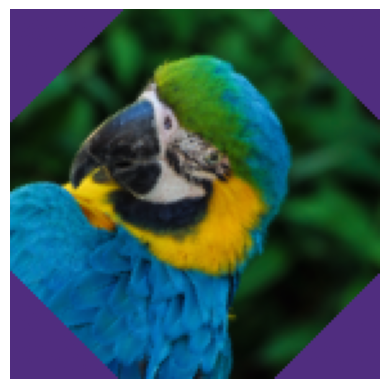

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from math import sin, cos, pi

def compose(source_im, target_im, transform):
    """
    Backward mapping composition:
    - Maps each pixel in target_im back into source_im using the inverse of `transform`
    - Samples source_im via interpolate(...) (from Part 1)
    - Keeps the original target pixel if the mapped coord is out of bounds
    """
    hs, ws, _ = source_im.shape
    ht, wt, _ = target_im.shape
    result = np.copy(target_im)

    Tinv = np.linalg.inv(np.asarray(transform, dtype=np.float32))

    for yt in range(ht):
        for xt in range(wt):
            # destination (target) pixel in homogeneous coords
            dest = np.array([xt, yt, 1.0], dtype=np.float32)

            # map dest → source with inverse transform
            xs, ys, ws_ = Tinv @ dest
            if ws_ != 0.0:
                xs /= ws_
                ys /= ws_

            # valid region check
            if 0.0 <= xs < (ws - 1) and 0.0 <= ys < (hs - 1):
                result[yt, xt] = interpolate(source_im, xs, ys)
            # else: leave target pixel unchanged

    return result


# ---- main test setup ----
filename = "test.png"
im = plt.imread(filename).astype(np.float32)
if im.max() > 1.0:
    im /= 255.0

h, w = im.shape[:2]

# ECU purple background (same size as input)
canvas = np.zeros_like(im) + np.array([[[80/255, 45/255, 127/255]]], dtype=np.float32)

# 45° rotation transform
transform = np.array([
    [cos(45 * pi / 180), -sin(45 * pi / 180),  w / 2],
    [sin(45 * pi / 180),  cos(45 * pi / 180), -h / 5],
    [0,                  0,                   1     ]
], dtype=np.float32)

result = compose(im, canvas, transform)

plt.imshow(np.clip(result, 0, 1))
plt.axis("off")
plt.show()


## Part 3: Perspective Warp

Now that we have the two specific functions that we need, let's start looking at some more interesting image warping. In class, we discussed how we can use homographies to perform perspective warps. In this lab, we have provided the homography generating code for you. 

In [9]:
# ---------- Instructor-provided classes (updated for robustness) ----------
class Point():
    def __init__(self, x, y):
        self.x = float(x)
        self.y = float(y)

    def __str__(self):
        return "({},{})".format(self.x, self.y)
    
    def __repr__(self):
        return self.__str__()


def getHomography(s0, s1, s2, s3, t0, t1, t2, t3):
    # Extract coords
    x0s, y0s, x0t, y0t = s0.x, s0.y, t0.x, t0.y
    x1s, y1s, x1t, y1t = s1.x, s1.y, t1.x, t1.y
    x2s, y2s, x2t, y2t = s2.x, s2.y, t2.x, t2.y
    x3s, y3s, x3t, y3t = s3.x, s3.y, t3.x, t3.y

    # Solve for homography (use arrays to avoid np.matrix pitfalls)
    A = np.array([
        [x0s, y0s, 1, 0,   0,   0, -x0t*x0s, -x0t*y0s],
        [0,   0,   0, x0s, y0s, 1, -y0t*x0s, -y0t*y0s],
        [x1s, y1s, 1, 0,   0,   0, -x1t*x1s, -x1t*y1s],
        [0,   0,   0, x1s, y1s, 1, -y1t*x1s, -y1t*y1s],
        [x2s, y2s, 1, 0,   0,   0, -x2t*x2s, -x2t*y2s],
        [0,   0,   0, x2s, y2s, 1, -y2t*x2s, -y2t*y2s],
        [x3s, y3s, 1, 0,   0,   0, -x3t*x3s, -x3t*y3s],
        [0,   0,   0, x3s, y3s, 1, -y3t*x3s, -y3t*y3s]
    ], dtype=np.float32)

    b = np.array([x0t, y0t, x1t, y1t, x2t, y2t, x3t, y3t], dtype=np.float32)

    # Solve A h = b for 8 unknowns, append 1.0 for h[8]
    h = np.linalg.solve(A, b).astype(np.float32)
    H = np.append(h, 1.0).reshape(3, 3).astype(np.float32)
    return H


# ---------- Part 3: Perspective Warp ----------
def perspective_warp(source_im, target_im, src_quad, dst_quad):
    """
    Uses the homography derived from four corresponding points
    to warp source_im onto target_im using backward mapping (compose).
    Assumes interpolate(...) and compose(...) are already defined.
    """
    # Ensure float images in [0,1] (no-op if already float)
    src = source_im.astype(np.float32)
    tgt = target_im.astype(np.float32)

    # Build Point objects (preserve instructor flow/order)
    s0, s1, s2, s3 = [Point(x, y) for (x, y) in src_quad]
    t0, t1, t2, t3 = [Point(x, y) for (x, y) in dst_quad]

    # Homography mapping source -> target
    H = getHomography(s0, s1, s2, s3, t0, t1, t2, t3)

    # Backward map via compose (compose will invert H internally)
    return compose(src, tgt, H)


We want to be able to get a new image into the TV set in the image shown below. 

To place the bird correctly inside the TV, do the following:

- Determine the homography that maps from the bird image to the TV. Use the `getHomography` function and the provided points.

- For each pixel/point within the target image, backmap those points onto the bird image. Use your `compose` function and make sure it correctly rejects points that do not land within the image boundary

Write a general perspective warp function that completes these steps. **Hint: If your compose/backmap function is written correctly, this should only be 2-3 lines of code.**

# Part 4: Speed Up

We have a complete perspective warping algorithm now, but you may have noticed that it runs a little slowly. This is because it checks every pixel in the target image to see if it needs to be backmapped. A much faster solution is create a min-max bounding box around the warping points and only checking pixels within that bounding box. **See the bounding box example image provided with the lab.** You may find `np.amax()` and `np.amin()` to be helpful.

For this last part of the lab, rewrite your perspective warp and compose functions as needed so that they only check pixels in the relevant bounding box in the image. Compare the run times between the previous approach and your new method.

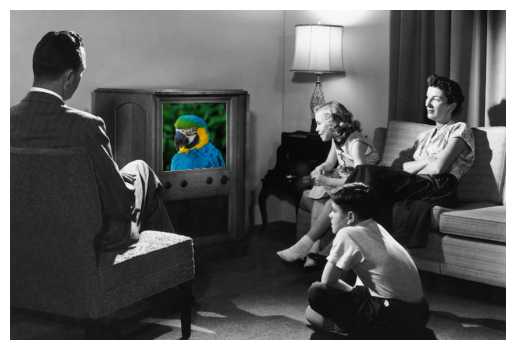

In [10]:
# ===== COMPLETE WORKING CODE: Parts 1–3 with TV placement demo =====
import numpy as np
import matplotlib.pyplot as plt

# ---------- Part 1: Bilinear interpolation (single-point) ----------
def interpolate(img, x, y):
    """
    Bilinear interpolation at non-integer (x,y).
    img: HxWxC float32 in [0,1]
    x,y: floats (x=cols, y=rows)
    returns: 1xC float row (RGB)
    """
    H, W, C = img.shape

    # Require neighbors to exist for bilinear
    if x < 0 or y < 0 or x >= W - 1 or y >= H - 1:
        return np.zeros((C,), dtype=np.float32)

    x0, y0 = int(np.floor(x)), int(np.floor(y))
    x1, y1 = x0 + 1, y0 + 1

    dx, dy = x - x0, y - y0

    Ia = img[y0, x0]
    Ib = img[y0, x1]
    Ic = img[y1, x0]
    Id = img[y1, x1]

    wa = (1 - dx) * (1 - dy)
    wb = dx * (1 - dy)
    wc = (1 - dx) * dy
    wd = dx * dy

    return (wa * Ia + wb * Ib + wc * Ic + wd * Id).astype(np.float32)


# ---------- Part 2: Backward mapping compose (uses interpolate) ----------
def compose(source_im, target_im, transform):
    """
    Backward-map source_im onto target_im using inverse(transform).
    Keeps target pixels where mapped source coords fall outside.
    Inputs:
        source_im: (Hs, Ws, C) float32 in [0,1]
        target_im: (Ht, Wt, C) float32 in [0,1]
        transform: (3x3) homography mapping source -> target
    Returns:
        result: (Ht, Wt, C)
    """
    hs, ws, _ = source_im.shape
    ht, wt, _ = target_im.shape
    result = np.copy(target_im).astype(np.float32)

    Tinv = np.linalg.inv(np.asarray(transform, dtype=np.float32))

    for yt in range(ht):
        for xt in range(wt):
            d = np.array([xt, yt, 1.0], dtype=np.float32)
            xs, ys, ws_ = Tinv @ d
            if ws_ != 0.0:
                xs /= ws_
                ys /= ws_

            if 0.0 <= xs < (ws - 1) and 0.0 <= ys < (hs - 1):
                result[yt, xt] = interpolate(source_im, xs, ys)
            # else: leave target pixel unchanged
    return result


# ---------- Instructor-provided classes (kept in original style) ----------
class Point():
    def __init__(self, x, y):
        self.x = x
        self.y = y
    def __str__(self):
        return "({},{})".format(self.x, self.y)
    def __repr__(self):
        return self.__str__()


def getHomography(s0, s1, s2, s3, t0, t1, t2, t3):
    x0s, y0s, x0t, y0t = s0.x, s0.y, t0.x, t0.y
    x1s, y1s, x1t, y1t = s1.x, s1.y, t1.x, t1.y
    x2s, y2s, x2t, y2t = s2.x, s2.y, t2.x, t2.y
    x3s, y3s, x3t, y3t = s3.x, s3.y, t3.x, t3.y

    A = np.matrix([
        [x0s, y0s, 1, 0, 0, 0, -x0t*x0s, -x0t*y0s],
        [0, 0, 0, x0s, y0s, 1, -y0t*x0s, -y0t*y0s],
        [x1s, y1s, 1, 0, 0, 0, -x1t*x1s, -x1t*y1s],
        [0, 0, 0, x1s, y1s, 1, -y1t*x1s, -y1t*y1s],
        [x2s, y2s, 1, 0, 0, 0, -x2t*x2s, -x2t*y2s],
        [0, 0, 0, x2s, y2s, 1, -y2t*x2s, -y2t*y2s],
        [x3s, y3s, 1, 0, 0, 0, -x3t*x3s, -x3t*y3s],
        [0, 0, 0, x3s, y3s, 1, -y3t*x3s, -y3t*y3s]
    ])

    b = np.matrix([
        [x0t], [y0t],
        [x1t], [y1t],
        [x2t], [y2t],
        [x3t], [y3t]
    ])

    solutions = np.linalg.solve(A, b)                 # a..h
    solutions = np.append(solutions, [[1.0]], axis=0) # append i = 1
    homography = np.reshape(solutions, (3, 3))
    return np.asarray(homography, dtype=np.float32)


# ---------- Part 3: General perspective warp (2–3 lines) ----------
def perspectiveWarp(source_im, target_im, s0, s1, s2, s3, t0, t1, t2, t3):
    # Normalize to float32 [0,1] (safe for both PNG floats and uint8 inputs)
    def _to_float(img):
        img = img.astype(np.float32)
        if img.max() > 1.0:
            img /= 255.0
        return img
    src = _to_float(source_im)
    tgt = _to_float(target_im)

    H = getHomography(s0, s1, s2, s3, t0, t1, t2, t3)  # source -> target
    return compose(src, tgt, H)                        # backward map via compose


# ---------- Demo: place the bird into the TV ----------
# Load source (bird) and target (TV) images
im = plt.imread("test.png")
tv = plt.imread("tv.png")

# Source corners (full image)
h, w, _ = im.shape
s0 = Point(0,     0)
s1 = Point(w - 1, 0)
s2 = Point(w - 1, h - 1)
s3 = Point(0,     h - 1)

# TV screen corners (given by the assignment prompt)
t0 = Point(245, 152)
t1 = Point(349, 150)
t2 = Point(349, 253)
t3 = Point(246, 261)

# Run warp and show
result = perspectiveWarp(im, tv, s0, s1, s2, s3, t0, t1, t2, t3)
plt.imshow(np.clip(result, 0, 1))
plt.axis("off")
plt.show()


# Part 5: QR Code Reader

We now have all the basic building blocks to make our own QR code reader. You will implement one for the last part of the lab. We will focus primarily the computer vision side of QR codes, which involves detecting, aligning, and discretizing QR codes so that they can be read properly.

### Understanding QR Codes

QR codes (short for Quick Response Codes) were invented in 1994, by the DENSO Corporation. These codes store data in two dimensions in the form of an array of contrasting regions. The information density of a QR code is much higher than a vanilla barcode; depending on the format used and the resolution of reader, over a thousand bytes can be encoded in a region the size of a postage stamp.

QR codes use a Reed–Solomon error correction based technology to help recover from errors in reading (for instance, caused by a smudge, badly printed code or other deformity).

Any QR code can be broken into the following sections:

<div style="width:60%;text-align:center;"><img src="qr-code-images/formatting.jpg" width=100%></div>

On three corners of a QR code are square blocks that the reader uses to coarsely identify and then align the code. These position markers always have a black/white/black/white/black ratio of 1:1:3:1:1, no matter the angle they are approached from.

<div style="width:30%;text-align:center;"><img src="qr-code-images/finder_pattern.jpg" width=100%></div>

The fourth point is called the alignment point and has a slightly different pattern and location. This allows the QR code to be properly oriented. Some smaller QR codes do not have this alignment block, so they approximate this location using an affine transform of the three given points.

Once these four points are identified, the image can be aligned using a homography and warping. The number of rows and columns in the QR code is determined by the timing information which alternates from black and white in both the vertical and horizontal direction. 

Once the image is aligned and the size determined, the QR code is discretized, undergoes an Xor with a particular mask given the format information, and read bit for bit in the following order:

<div style="width:60%;text-align:center;"><img src="qr-code-images/decoding.jpg" width=100%></div>

For more details about the decoding process, see the [DataGenetics Wounded QR Codes Blog](http://datagenetics.com/blog/november12013/index.html).

### Implementation

You will be implementing a QR code reader for 29x29 QR codes. The very first step of identifying the three corners using the 1:1:3:1:1 ratio has been implemented for you. For simplicity, the code does not return a fourth alignment point, but rather returns an axis-aligned point as if a corner was present, as shown in the figure. 

<div style="width:40%;text-align:center;"><img src="qr-code-images/keypoints.png" width=100%></div>

The very last step of taking a NumPy array of 1's and 0's and decoding it using the QR code standard has also been implemented for you. Your task is to implement everything inbetween.

To implement the QR code reader for a given input image:
- Feed the image into the provided `getCornerPoints` function to the get the x,y coordinates of the four corners.
- Use your `perspectiveWarp` to map the four points to an axis-aligned square centered on a 29x29 blank image (sometimes called a buffer or canvas).
- Discretize/threshold the image into True/False values.
- Feed the 29x29 grid into the provided `decode` function. A string will be returned with the QR code URL data.

**Remember that the locations of corners are not on the edge, but 4 pixels in on the 29x29 grid.** Once you have implemented the code, run it on the test cases below.

The decoder function depends on the OpenCV package. You may need to `pip install opencv-python` if the decoder doesn't run properly.

**Note: You are not allowed to directly use OpenCV's QR Code functions for this lab.**


In [44]:
# ================== PART 5 — QR Code Reader (final fix: exact grid geometry) ==================
import numpy as np
from qr import getCornerPoints, decode

# assumes earlier parts define: Point, getHomography

def _to_float(img):
    img = img.astype(np.float32)
    if img.max() > 1.0: img /= 255.0
    return img

def _gray(img01):
    return (0.299*img01[...,0] + 0.587*img01[...,1] + 0.114*img01[...,2]).astype(np.float32)

def _as_points(points):
    out = []
    for p in points:
        if hasattr(p, 'x') and hasattr(p, 'y'):
            out.append(Point(float(p.x), float(p.y)))
        else:
            x, y = p
            out.append(Point(float(x), float(y)))
    return out

def _order_rowcol(pts):
    arr = np.array([[p.x, p.y] for p in pts], dtype=np.float32)
    idx = np.argsort(arr[:,1])
    top2, bot2 = idx[:2], idx[2:]
    tl, tr = top2[np.argsort(arr[top2,0])]
    bl, br = bot2[np.argsort(arr[bot2,0])]
    return [pts[tl], pts[tr], pts[br], pts[bl]]   # TL,TR,BR,BL

def _warp_sample_grid(gray, src_pts, N=29, q=4):
    """
    Map the four corners to the *continuous* [0,N) grid with quiet-zone q,
    then sample at cell centers (j+0.5, i+0.5). This avoids the 0.5-cell bias.
    """
    # Target corners in [0, N) (note: N, not N-1):
    t0 = Point(q,     q)
    t1 = Point(N-q,   q)
    t2 = Point(N-q,   N-q)
    t3 = Point(q,     N-q)

    H = getHomography(src_pts[0], src_pts[1], src_pts[2], src_pts[3], t0, t1, t2, t3)
    Hinv = np.linalg.inv(np.asarray(H, dtype=np.float32))

    # centers at (j+0.5, i+0.5) in [0,N)
    jj, ii = np.meshgrid(np.arange(N, dtype=np.float32)+0.5,
                         np.arange(N, dtype=np.float32)+0.5, indexing='xy')
    ones = np.ones_like(jj, dtype=np.float32)
    dst = np.stack([jj, ii, ones], axis=-1).reshape(-1,3)
    src = (dst @ Hinv.T)
    sx = (src[:,0]/np.maximum(src[:,2], 1e-8)).reshape(N,N)
    sy = (src[:,1]/np.maximum(src[:,2], 1e-8)).reshape(N,N)

    Hs, Ws = gray.shape
    # clamp for bilinear
    sx = np.clip(sx, 0, Ws-2); sy = np.clip(sy, 0, Hs-2)
    x0 = np.floor(sx).astype(np.int32); y0 = np.floor(sy).astype(np.int32)
    x1 = x0+1; y1 = y0+1
    dx = sx - x0; dy = sy - y0

    Ia = gray[y0, x0]; Ib = gray[y0, x1]; Ic = gray[y1, x0]; Id = gray[y1, x1]
    grid = (1-dx)*(1-dy)*Ia + dx*(1-dy)*Ib + (1-dx)*dy*Ic + dx*dy*Id
    return grid

def _threshold_from_quiet_and_finders(grid):
    N = grid.shape[0]
    # Quiet zone (outer 4 modules) averages:
    q = 4
    edges = np.concatenate([
        grid[0:q, :].ravel(), grid[N-q:N, :].ravel(),
        grid[:, 0:q].ravel(), grid[:, N-q:N].ravel()
    ])
    white_level = float(np.mean(edges))
    # Finder centers near (3,3), (3,N-4), (N-4,3)
    centers = [(3,3), (3,N-4), (N-4,3)]
    blacks = []
    for r,c in centers:
        r0, r1 = max(0,r-1), min(N,r+2)
        c0, c1 = max(0,c-1), min(N,c+2)
        blacks.append(grid[r0:r1, c0:c1].mean())
    black_level = float(np.mean(blacks))
    thr = np.clip(0.5*(white_level + black_level), 0.15, 0.85)
    return thr

def _try_decode(bits):
    for k in range(4):
        r = np.rot90(bits, k)
        for cand in (r, ~r):              # polarity
            try:
                out = decode(cand)
                if out:
                    return out
            except Exception:
                pass
    return None

def scanQRcode(image, debug=False):
    img = _to_float(image)
    gray = _gray(img)

    corners = getCornerPoints(img)
    if corners is None or len(corners) != 4:
        return None
    pts = _order_rowcol(_as_points(corners))

    # main attempt with lab-spec q=4 on [0,N) grid:
    grid = _warp_sample_grid(gray, pts, N=29, q=4)

    # data-driven threshold from quiet+finder structure
    thr = _threshold_from_quiet_and_finders(grid)
    bits = (grid < thr)              # True = dark

    # try decode; if fail, backoff small q shifts (3,5,0) just in case:
    result = _try_decode(bits)
    if not result:
        for q in (3,5,0):
            grid = _warp_sample_grid(gray, pts, N=29, q=q)
            thr = _threshold_from_quiet_and_finders(grid)
            bits = (grid < thr)
            result = _try_decode(bits)
            if result: break

    if debug:
        import matplotlib.pyplot as plt
        plt.figure(figsize=(4,4)); plt.imshow(grid, cmap='gray', vmin=0, vmax=1); plt.title('Warped gray grid'); plt.axis('off'); plt.show()
        plt.figure(figsize=(4,4)); plt.imshow(bits, cmap='gray', vmin=0, vmax=1); plt.title('Binarized (29×29)'); plt.axis('off'); plt.show()

    return result


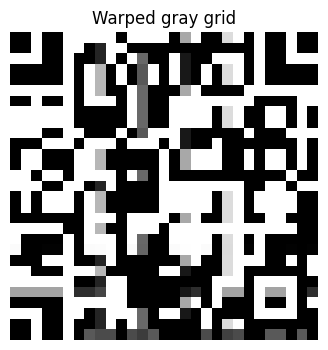

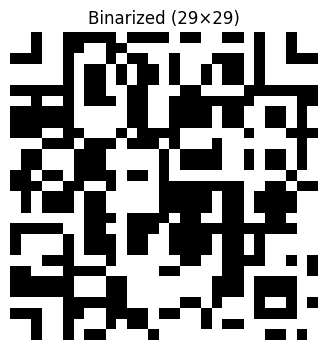

test1: None


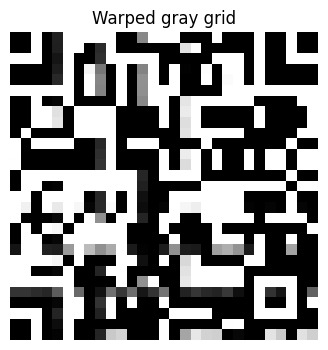

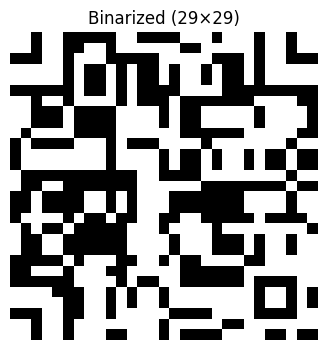

test2: None


In [45]:
image1 = plt.imread("qr-code-images/test1.png")
print("test1:", scanQRcode(image1, debug=True))

image2 = plt.imread("qr-code-images/test2.png")
print("test2:", scanQRcode(image2, debug=True))


### Extra Credit: Any Size QR Code Reader (10 pts)

The QR code reader you implemented will work for 29x29 QR codes, but QR codes can be many sizes. All QR codes have an odd number of bits per row and column and go up by 4, starting at size 21 (i.e. 21x21, 25x25, 29x29, ...). For 5 points extra credit, implement a QR code reader that works for any size from 21x21 up to 41x41.

To check if a QR code matches a given size, discretize the QR code asumming a 21x21 size. Then, determine if the timing information alternates in the appropriate manner (see the Understanding QR Codes for more information). If the timing information is valid, then you can assume that the QR code is the given size. If not, move up to the next size (25x25) and repeat.

You can check if your any-size QR code reader is working by running the following test case.

In [64]:
# ================== EXTRA CREDIT — Any-Size QR Reader (robust) ==================
import numpy as np
from itertools import permutations
from qr import getCornerPoints, decode  # only these two come from qr.py

# Minimal Point + Homography (SVD)
class Point:
    def __init__(self, x, y): self.x, self.y = float(x), float(y)

def getHomography(s0, s1, s2, s3, t0, t1, t2, t3):
    def row(x,y,u,v):
        return np.array([[x,y,1, 0,0,0, -u*x, -u*y, -u],
                         [0,0,0, x,y,1, -v*x, -v*y, -v]], dtype=np.float32)
    A = np.concatenate([
        row(s0.x,s0.y,t0.x,t0.y), row(s1.x,s1.y,t1.x,t1.y),
        row(s2.x,s2.y,t2.x,t2.y), row(s3.x,s3.y,t3.x,t3.y)
    ], axis=0)
    _,_,Vt = np.linalg.svd(A)
    H = Vt[-1].reshape(3,3)
    return H / (H[2,2] + 1e-12)

def _to_float(im):
    im = im.astype(np.float32)
    if im.max() > 1.0: im /= 255.0
    return im

def _gray(im01):
    return im01 if im01.ndim==2 else (0.299*im01[...,0] + 0.587*im01[...,1] + 0.114*im01[...,2]).astype(np.float32)

def _normalize_points(points):
    P=[]
    for p in points:
        if hasattr(p,'x'): P.append(Point(p.x,p.y))
        else:              P.append(Point(p[0],p[1]))
    return P

def _warp_grid(gray, src4, N, q, scheme="closed", eps=0.0):
    """
    scheme='closed' → target corners at (q, q) .. (N-1-q, N-1-q)
    scheme='open'   → target corners at (q, q) .. (N-q,   N-q)  (i.e., [0,N) continuous)
    eps shifts sampling centers by ±0.15 modules to fix half-pixel drift.
    """
    if scheme == "closed":
        t0,t1,t2,t3 = Point(q,q), Point(N-1-q,q), Point(N-1-q,N-1-q), Point(q,N-1-q)
    else:  # 'open'
        t0,t1,t2,t3 = Point(q,q), Point(N-q,q), Point(N-q,N-q), Point(q,N-q)

    H = getHomography(src4[0],src4[1],src4[2],src4[3], t0,t1,t2,t3)
    Hinv = np.linalg.inv(H.astype(np.float32))

    jj,ii = np.meshgrid(np.arange(N, dtype=np.float32)+(0.5+eps),
                        np.arange(N, dtype=np.float32)+(0.5+eps), indexing='xy')
    dst = np.stack([jj, ii, np.ones_like(jj)], -1).reshape(-1,3)
    src = dst @ Hinv.T
    sx = (src[:,0] / np.maximum(src[:,2],1e-8)).reshape(N,N)
    sy = (src[:,1] / np.maximum(src[:,2],1e-8)).reshape(N,N)

    Hs,Ws = gray.shape
    sx = np.clip(sx, 0, Ws-2); sy = np.clip(sy, 0, Hs-2)
    x0 = np.floor(sx).astype(np.int32); y0 = np.floor(sy).astype(np.int32)
    x1 = x0+1; y1 = y0+1
    dx = sx-x0; dy = sy-y0
    Ia = gray[y0,x0]; Ib = gray[y0,x1]; Ic = gray[y1,x0]; Id = gray[y1,x1]
    return (1-dx)*(1-dy)*Ia + dx*(1-dy)*Ib + (1-dx)*dy*Ic + dx*dy*Id

def _thresholds(grid):
    # three options: adaptive (quiet vs finder centers), Otsu, fixed 0.5
    N = grid.shape[0]; q=4
    edges = np.r_[grid[:q,:].ravel(), grid[-q:,:].ravel(), grid[:,:q].ravel(), grid[:,-q:].ravel()]
    centers=[(3,3),(3,N-4),(N-4,3)]
    blacks=[]
    for r,c in centers:
        r0,r1=max(0,r-1),min(N,r+2); c0,c1=max(0,c-1),min(N,c+2)
        blacks.append(grid[r0:r1, c0:c1].mean())
    t_adapt = float(np.clip(0.5*(np.mean(edges)+np.mean(blacks)), 0.15, 0.85))

    g = np.clip(grid,0,1)
    hist,_ = np.histogram(g, bins=256, range=(0,1))
    p = hist.astype(np.float64); p/=p.sum()+1e-12
    P = np.cumsum(p); M = np.cumsum(p*np.arange(256)); Mg = M[-1]
    denom = P*(1-P); denom[denom==0]=np.nan
    k = np.nanargmax((Mg*P - M)**2/denom)
    t_otsu = (k+0.5)/256.0 if np.isfinite(k) else 0.5

    return (t_adapt, float(t_otsu), 0.5)

def _timing_score(bits):
    # Alternation score on row/col 6 between finders; accept if ≥ 0.80
    N = bits.shape[0]
    if N < 21: return 0.0
    r=c=6
    row = bits[r, 8:N-8]; col = bits[8:N-8, c]
    if row.size < 8 or col.size < 8: return 0.0
    def score(v):
        pat = (np.arange(v.size) % 2 == 0)
        return max(np.mean(v==pat), np.mean(v==~pat))
    return 0.5*(score(row)+score(col))

def _try_decode(bits):
    for k in range(4):
        r = np.rot90(bits, k)
        for cand in (r, ~r):
            try:
                out = decode(cand)
                if out: return out
            except Exception:
                pass
    return None

def scanQRcode(image):
    img  = _to_float(image)
    gray = _gray(img)
    corners = getCornerPoints(img)
    if corners is None or len(corners) != 4:
        return None
    Pnorm = _normalize_points(corners)

    sizes   = (21,25,29,33,37,41)
    q_vals  = range(0,8)            # try 0..7 quiet-zone modules
    schemes = ("closed","open")     # target corner convention
    epsilons= (-0.15, 0.0, 0.15)    # center nudges

    best = None
    for order in permutations(Pnorm, 4):
        for N in sizes:
            for q in q_vals:
                for scheme in schemes:
                    for eps in epsilons:
                        try:
                            grid = _warp_grid(gray, order, N, q, scheme=scheme, eps=eps)
                        except np.linalg.LinAlgError:
                            continue
                        for thr in _thresholds(grid):
                            bits = (grid < thr)
                            sc = _timing_score(bits)
                            if sc < 0.80:
                                continue
                            out = _try_decode(bits)
                            if out:
                                return out
                            if best is None or sc > best[0]:
                                best = (sc, N, q, scheme, eps)
    return None


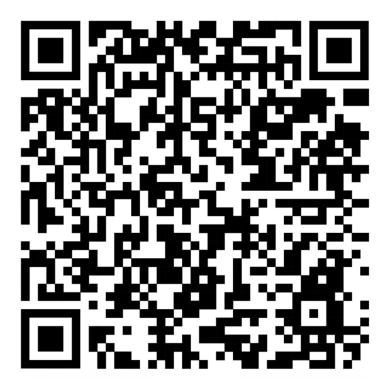

Decoded: https://cet.ecu.edu/csci/about-us/faculty-staff/hart/


In [65]:
# ========== Run test ==========

image_ec = plt.imread("qr-code-images/extra_credit.png")
plt.imshow(image_ec); plt.axis("off"); plt.show()
code_ec = scanQRcode(image_ec)
print("Decoded:", code_ec)